# *Telco Customer Churn Prediction Model*

######*Goal: To build a machine learning classification model that identifies which customers are most likely to cancel their service, enabling targeted retention strategies*.

## *What This Notebook Covers:*

1. **Data Ingestion & Setup:** Importing necessary Python libraries (Pandas, Scikit-Learn) and loading the Kaggle dataset directly into Colab.
2. **Exploratory Data Analysis (EDA):** Visualizing distributions of numerical and categorical variables to understand the baseline churn rate.
3. **Data Cleaning:** Handling missing, empty, or incorrectly formatted values (such as coercing the `TotalCharges` column from strings to numeric values).
4. **Target Definition:** Converting the binary target variable (`Churn`) from 'Yes'/'No' text into 1s and 0s.
5. **Feature Engineering:** Analyzing customer demographics, account information, and service usage to extract meaningful predictive signals.
6. **Categorical Encoding:** Applying one-hot encoding or label encoding to transform text categories (like "Month-to-month contract" or "Fiber optic") into machine-readable numeric formats.
7. **Data Splitting:** Dividing the dataset into an 80% training set to teach the algorithm and a 20% testing set to evaluate its performance.
8. **Model Training:** Initializing and training classification algorithms, such as a Random Forest Classifier or Logistic Regression, on the prepared training data.
9. **Performance Evaluation:** Testing the model's accuracy, precision, recall, and F1-score against the unseen test data using a confusion matrix.
10. **Feature Importance & Business Insights:** Extracting the top variables that drive churn (like contract type or tenure length) to provide actionable recommendations for the business.

# *1.Import Libraries*

In [1]:
# Data manipulation and arrays
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and model selection
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning Algorithms
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Model Saving
import joblib
import warnings

# Ignore minor warnings to keep the notebook clean
warnings.filterwarnings("ignore")

#*2. Load the Datasets*

In [11]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path)

df = pd.read_csv(os.path.join(path, "WA_Fn-UseC_-Telco-Customer-Churn.csv"))
df.head()


Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Path to dataset files: /kaggle/input/telco-customer-churn


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [5]:
df.shape

(7043, 21)

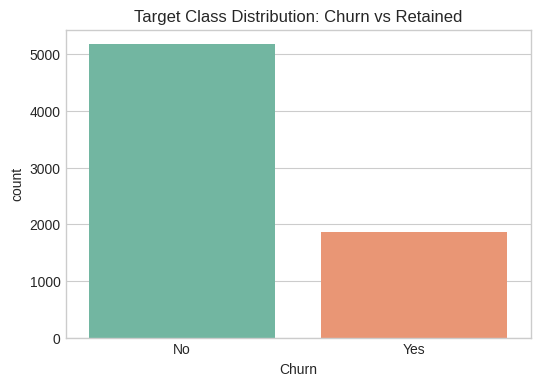


Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [6]:
# Set a clean visual style
plt.style.use("seaborn-v0_8-whitegrid")

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn', palette='Set2')
plt.title('Target Class Distribution: Churn vs Retained')
plt.show()

# Print exact percentages
print("\nChurn Percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)

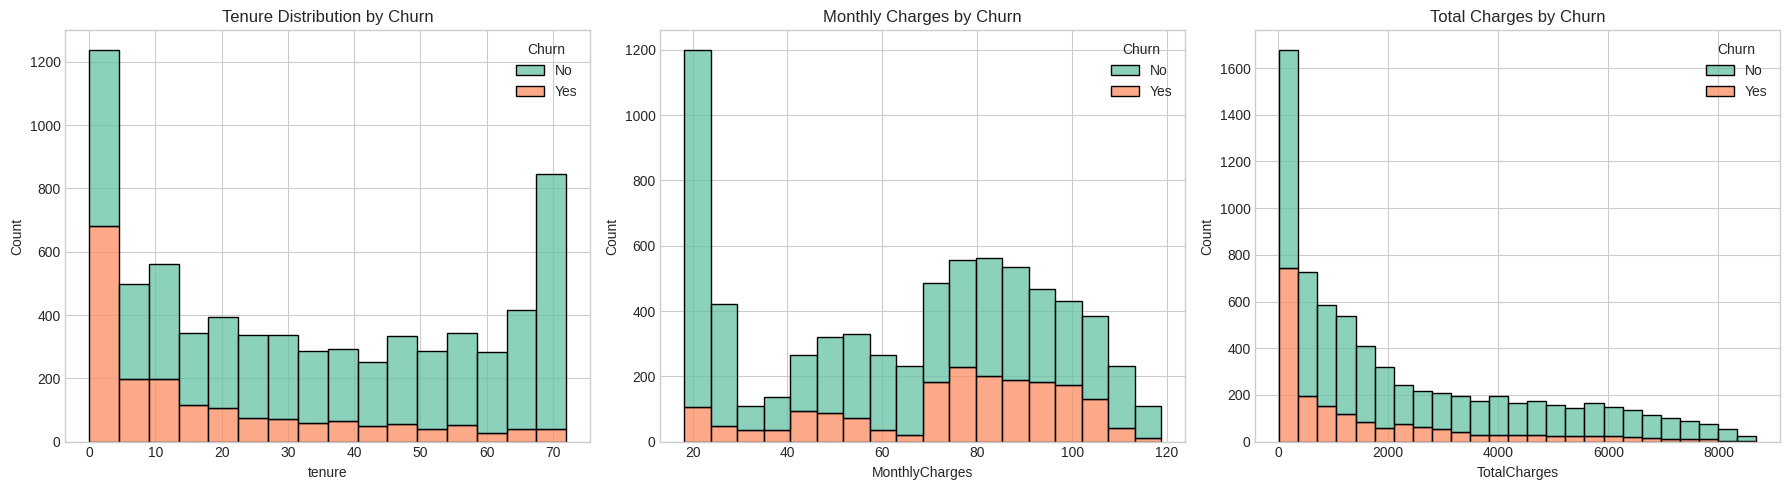

In [7]:
# Convert TotalCharges to numeric, coercing blank spaces to NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Plot the three continuous numeric features
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(data=df, x='tenure', hue='Churn', multiple="stack", ax=axes[0], palette='Set2')
axes[0].set_title('Tenure Distribution by Churn')

sns.histplot(data=df, x='MonthlyCharges', hue='Churn', multiple="stack", ax=axes[1], palette='Set2')
axes[1].set_title('Monthly Charges by Churn')

sns.histplot(data=df, x='TotalCharges', hue='Churn', multiple="stack", ax=axes[2], palette='Set2')
axes[2].set_title('Total Charges by Churn')

plt.tight_layout()
plt.show()

# *3. Exploratory Data Analysis*

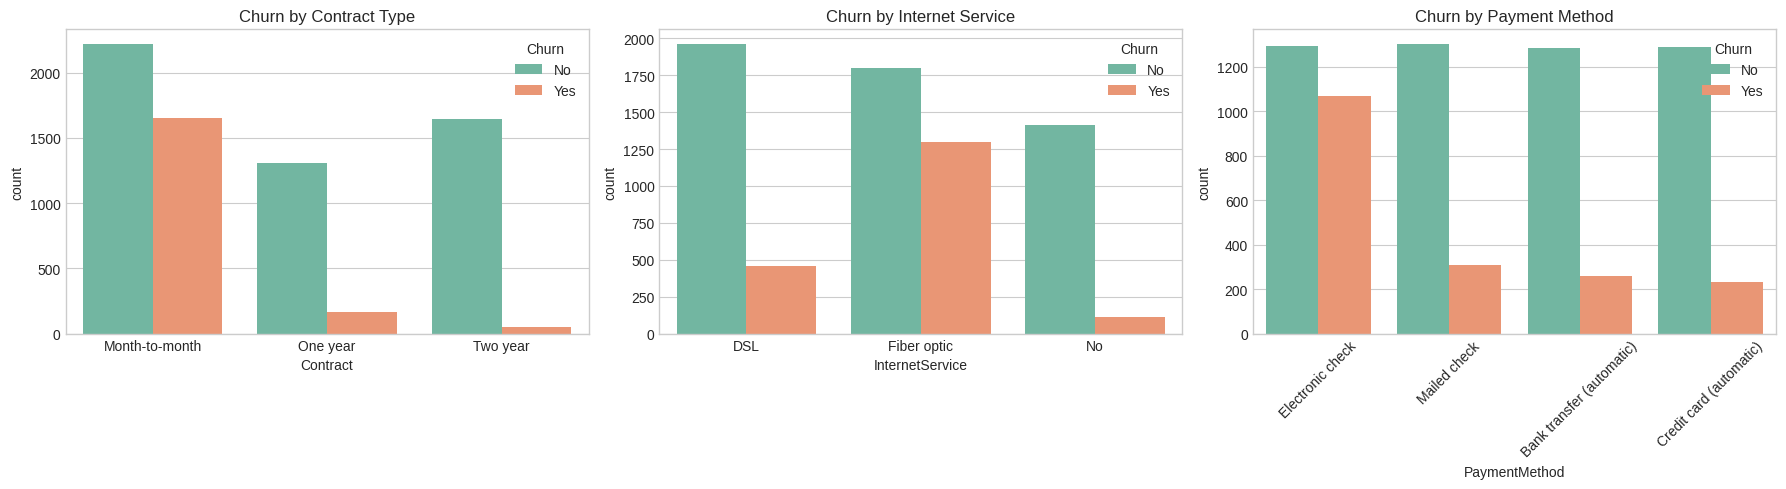

In [8]:
# Create a figure with 3 subplots for categorical variables
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Contract Type
sns.countplot(data=df, x='Contract', hue='Churn', ax=axes[0], palette='Set2')
axes[0].set_title('Churn by Contract Type')

# Plot 2: Internet Service Type
sns.countplot(data=df, x='InternetService', hue='Churn', ax=axes[1], palette='Set2')
axes[1].set_title('Churn by Internet Service')

# Plot 3: Payment Method
sns.countplot(data=df, x='PaymentMethod', hue='Churn', ax=axes[2], palette='Set2')
axes[2].set_title('Churn by Payment Method')
axes[2].tick_params(axis='x', rotation=45) # Rotate labels so they don't overlap

plt.tight_layout()
plt.show()

## *4. Data Preprocessing*

In [13]:
# 1. Clean TotalCharges & Remove customerID
# Convert TotalCharges to float and fill the 11 blank spaces with 0
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)

# Drop customerID if present
if 'customerID' in df.columns:
    df = df.drop(columns=['customerID'])

# 2. Target Definition & Stratified Split
# Map Churn to binary if it hasn't been mapped yet
if df['Churn'].dtype == 'object':
    df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

# 3. Define Clean Feature Categories
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

# 4. Build Preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ]
)

preprocessor

Training set size: 5634 samples
Test set size: 1409 samples


ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['tenure', 'MonthlyCharges', 'TotalCharges']),
                                ('cat',
                                 OneHotEncoder(drop='first',
                                               handle_unknown='ignore'),
                                 ['gender', 'Partner', 'Dependents',
                                  'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                                  'StreamingMovies', 'Contract',
                                  'PaperlessBilling', 'PaymentMethod'])])

# *5. Model Training*

In [14]:
# Create the full pipeline connecting the preprocessor to a Random Forest model
# class_weight='balanced' helps the model pay extra attention to the minority class (churners)
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42))
])

# Train the model on the training data
print("Training Random Forest model...")
rf_pipeline.fit(X_train, y_train)
print("Training complete.\n")

Training Random Forest model...
Training complete.



# *6. Model Evaluation*

Classification Report:
              precision    recall  f1-score   support

Retained (0)       0.82      0.89      0.85      1035
 Churned (1)       0.61      0.47      0.53       374

    accuracy                           0.78      1409
   macro avg       0.71      0.68      0.69      1409
weighted avg       0.76      0.78      0.77      1409



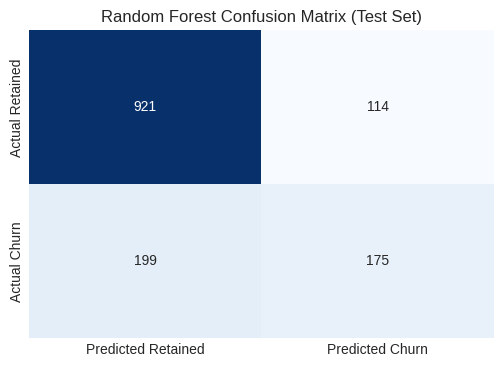

In [15]:
# Predict on the unseen test data
y_pred = rf_pipeline.predict(X_test)

# Print the classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Retained (0)', 'Churned (1)']))

# Plot a professional Confusion Matrix
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Retained', 'Predicted Churn'],
            yticklabels=['Actual Retained', 'Actual Churn'])
plt.title('Random Forest Confusion Matrix (Test Set)')
plt.show()

# *7. Feature Importance & Business Insights*

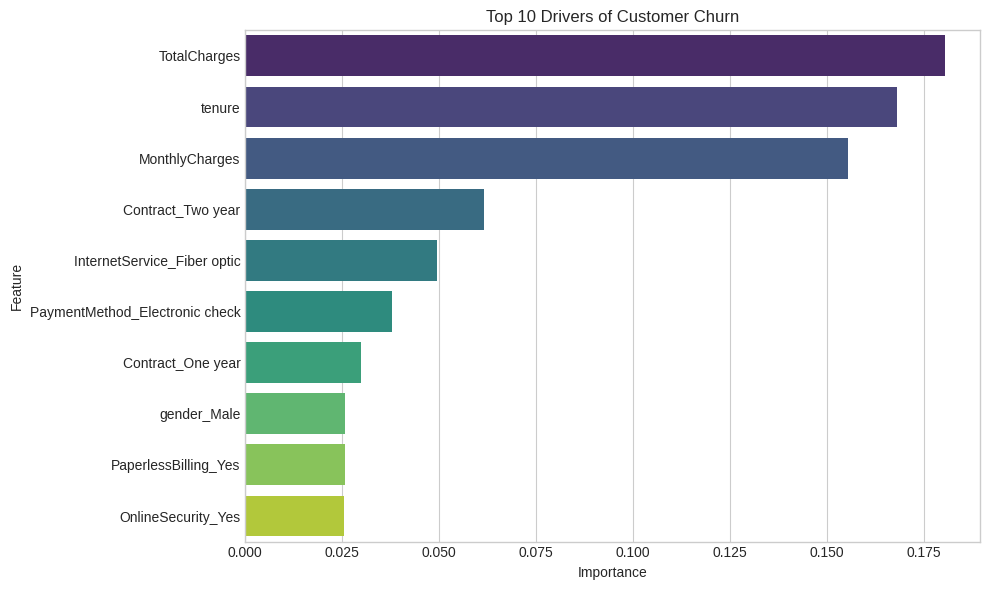

In [16]:
# Extract the trained model and preprocessor from the pipeline
model = rf_pipeline.named_steps['classifier']
preprocessor = rf_pipeline.named_steps['preprocessor']

# Get numerical feature names
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

# Get one-hot encoded categorical feature names
cat_encoder = preprocessor.named_transformers_['cat']
cat_features = cat_encoder.get_feature_names_out(cat_cols)

# Combine all feature names
all_features = num_cols + list(cat_features)

# Create a DataFrame of features and their importance scores
feature_importances = pd.DataFrame({
    'Feature': all_features,
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Plot the Top 10 most important features
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importances.head(10), x='Importance', y='Feature', palette='viridis')
plt.title('Top 10 Drivers of Customer Churn')
plt.tight_layout()
plt.show()

# *8. Export the Model for the Web UI*

In [17]:
import joblib

# Save the entire pipeline to a file
model_filename = 'telco_churn_pipeline.pkl'
joblib.dump(rf_pipeline, model_filename)

print(f"Success! Model saved as: {model_filename}")

Success! Model saved as: telco_churn_pipeline.pkl
